# CodeAlpha - Sales Prediction using Python

This project analyzes advertising data and builds a machine learning model to predict sales. It includes data cleaning, exploratory data analysis, visualization, feature selection, model training, evaluation, and business insights.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print('Libraries imported successfully!')

Libraries imported successfully!


## 1. Load the Dataset

In [24]:
# CodeAlpha-style advertising and sales dataset
url = 'https://raw.githubusercontent.com/selva86/datasets/master/Advertising.csv'
df = pd.read_csv(url)

# Remove the extra index column if it is present.
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print('Dataset loaded successfully!')
print('Shape:', df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (200, 4)


,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


## 2. Understand the Data

In [25]:
print('Column names:')
print(df.columns.tolist())

print('\nData types:')
print(df.dtypes)

print('\nSummary statistics:')
display(df.describe())

Column names:
['TV', 'radio', 'newspaper', 'sales']

Data types:
TV           float64
radio        float64
newspaper    float64
sales        float64
dtype: object

Summary statistics:


,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


## 3. Data Cleaning

In [26]:
print('Missing values before cleaning:')
print(df.isnull().sum())

df = df.drop_duplicates().copy()

print('\nMissing values after cleaning:')
print(df.isnull().sum())
print('\nShape after cleaning:', df.shape)

Missing values before cleaning:
TV           0
radio        0
newspaper    0
sales        0
dtype: int64

Missing values after cleaning:
TV           0
radio        0
newspaper    0
sales        0
dtype: int64

Shape after cleaning: (200, 4)


## 4. Exploratory Data Analysis

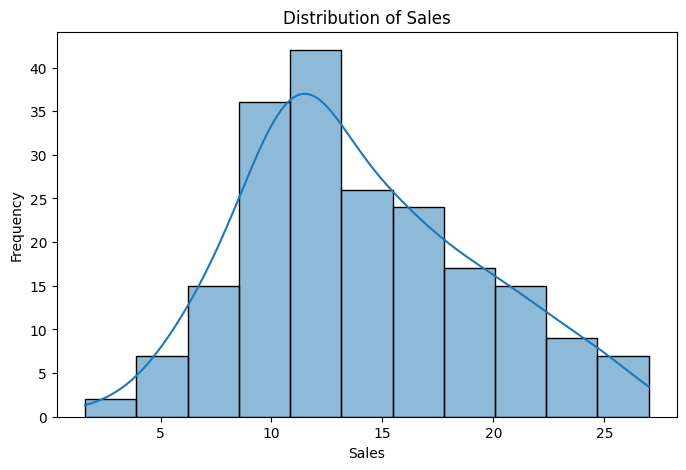

In [27]:
plt.figure(figsize=(8, 5))
sns.histplot(df['sales'], kde=True)
plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()

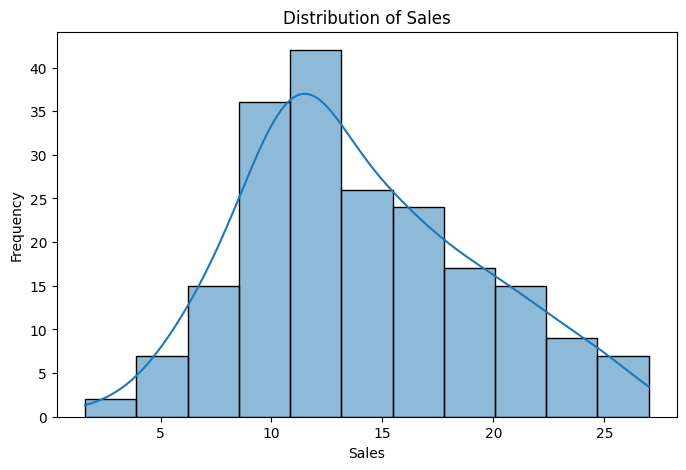

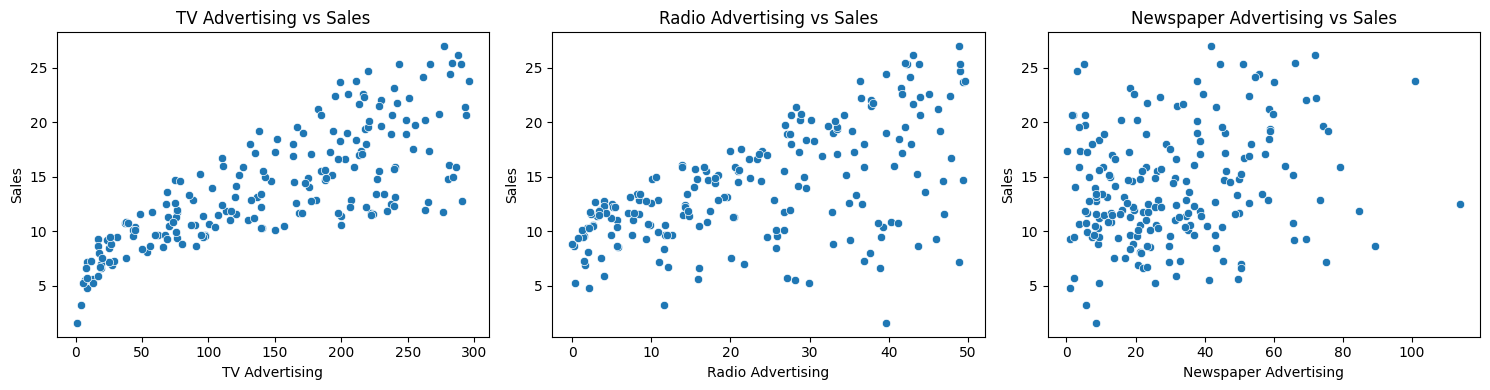

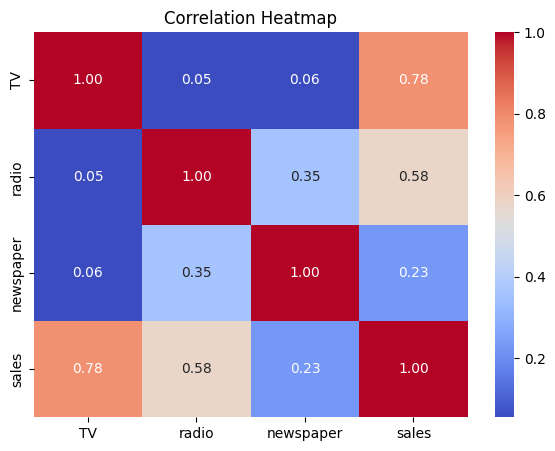

In [28]:
# 4. Exploratory Data Analysis

# Distribution of Sales
plt.figure(figsize=(8, 5))
sns.histplot(df['sales'], kde=True)

plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()


# Advertising vs Sales
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# TV Advertising vs Sales
sns.scatterplot(data=df, x='TV', y='sales', ax=axes[0])
axes[0].set_title('TV Advertising vs Sales')
axes[0].set_xlabel('TV Advertising')
axes[0].set_ylabel('Sales')


# Radio Advertising vs Sales
sns.scatterplot(data=df, x='radio', y='sales', ax=axes[1])
axes[1].set_title('Radio Advertising vs Sales')
axes[1].set_xlabel('Radio Advertising')
axes[1].set_ylabel('Sales')


# Newspaper Advertising vs Sales
sns.scatterplot(data=df, x='newspaper', y='sales', ax=axes[2])
axes[2].set_title('Newspaper Advertising vs Sales')
axes[2].set_xlabel('Newspaper Advertising')
axes[2].set_ylabel('Sales')

plt.tight_layout()
plt.show()


# Correlation Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.show()

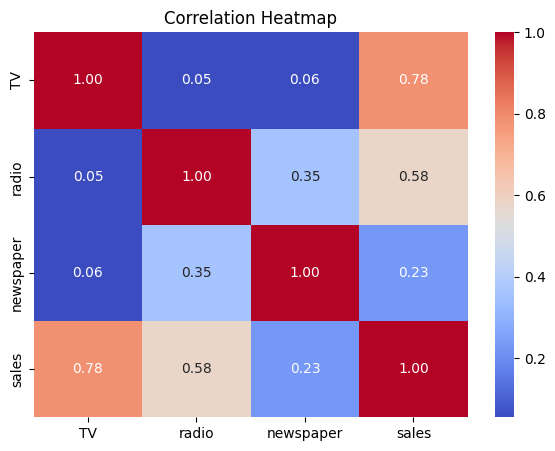

In [29]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

## 5. Feature Selection

In [30]:
# 5. Feature Selection

X = df[['TV', 'radio', 'newspaper']]
y = df['sales']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Features selected successfully!")
print("Features:", X.columns.tolist())
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Features selected successfully!
Features: ['TV', 'radio', 'newspaper']
Training samples: 160
Testing samples: 40


## 6. Train Linear Regression Model

In [31]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

print('Linear Regression model trained successfully!')

Linear Regression model trained successfully!


## 7. Train Random Forest Model

In [32]:
random_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)
random_forest_model.fit(X_train, y_train)
rf_pred = random_forest_model.predict(X_test)

print('Random Forest model trained successfully!')

Random Forest model trained successfully!


## 8. Model Evaluation

In [33]:
def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)
    return [name, mae, rmse, r2]

results = pd.DataFrame([
    evaluate_model('Linear Regression', y_test, linear_pred),
    evaluate_model('Random Forest', y_test, rf_pred)
], columns=['Model', 'MAE', 'RMSE', 'R2 Score'])

display(results)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.460757,1.781600,0.899438
1,Random Forest,0.628713,0.757235,0.981833


## 9. Actual vs Predicted Sales

,Actual Sales,Predicted Sales
0,16.9,17.7615
1,22.4,21.6665
2,21.4,20.6595
3,7.3,6.7395
4,24.7,23.0960
5,12.6,13.5155
6,22.3,22.4860
7,8.4,9.6625
8,11.5,11.8545
9,14.9,15.5040


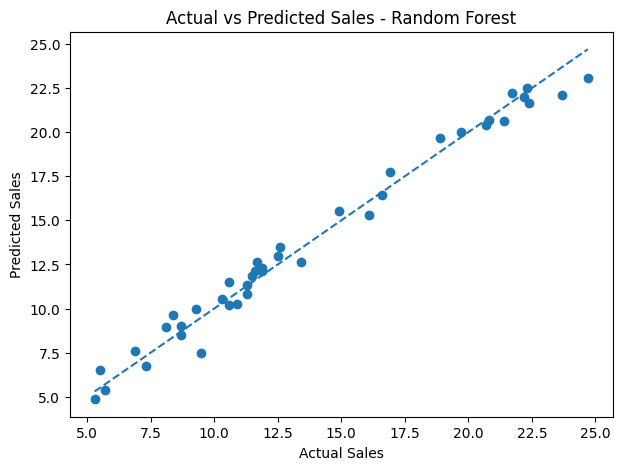

In [34]:
comparison = pd.DataFrame({
    'Actual Sales': y_test.values,
    'Predicted Sales': rf_pred
})

display(comparison.head(15))

plt.figure(figsize=(7, 5))
plt.scatter(y_test, rf_pred)
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('Actual vs Predicted Sales - Random Forest')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle='--')
plt.show()

## 10. Advertising Feature Importance

,Importance
TV,0.624727
radio,0.362119
newspaper,0.013153


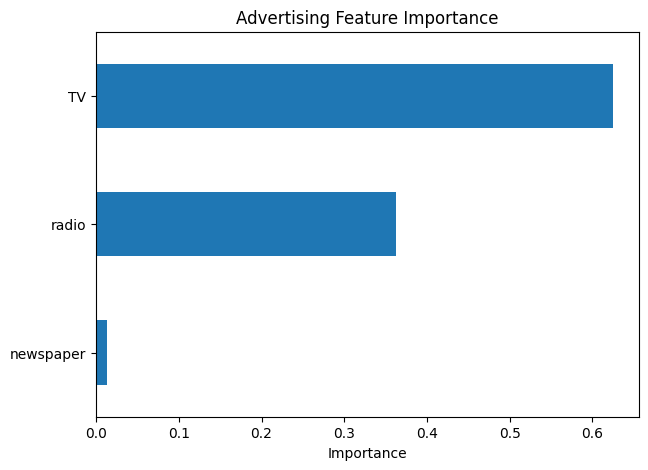

In [35]:
importance = pd.Series(
    random_forest_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

display(importance.to_frame('Importance'))

plt.figure(figsize=(7, 5))
importance.sort_values().plot(kind='barh')
plt.title('Advertising Feature Importance')
plt.xlabel('Importance')
plt.show()

## 11. Sales Prediction Example

In [36]:
# Example prediction using new advertising spending values.
# Replace these values with your own planned advertising budget if needed.
new_advertising = pd.DataFrame({
    'TV': [150],
    'radio': [25],
    'newspaper': [20]
})

predicted_sales = random_forest_model.predict(new_advertising)[0]
print(f'Predicted sales for the example advertising budget: {predicted_sales:.2f}')

Predicted sales for the example advertising budget: 15.16


## 12. Key Insights

- Advertising spending can be studied to understand its relationship with sales.
- The correlation analysis helps identify which advertising channels have stronger relationships with sales.
- Linear Regression provides a simple baseline model for sales prediction.
- Random Forest can capture non-linear relationships and is compared with Linear Regression using MAE, RMSE and R².
- The feature importance output helps identify which advertising variables contribute more to the model's predictions.
- These results can support marketing decisions, but model predictions should be considered together with real business factors.

## Conclusion

In this project, advertising data was cleaned and explored using Python. Different visualizations were used to understand the relationship between advertising channels and sales. Linear Regression and Random Forest Regression models were trained and evaluated. The better-performing model was then used for sales prediction and feature importance analysis. This project shows how data science and machine learning can help businesses understand advertising performance and estimate future sales.